In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
from features import build_features

train, test, sub = common.load_data()

print("Train:", train.shape)
print("Test:", test.shape)
print("So lop:", train["Class"].nunique())
print("Gia tri thieu:", train.isna().sum().sum())

Train: (14396, 18)
Test: (3600, 17)
So lop: 11
Gia tri thieu: 5483



# CHALLENGE 2 - MUSIC GENRE CLASSIFICATION

## PHAN C: PREPROCESSING & FEATURE ENGINEERING

### 1. Muc tieu

Xay dung va danh gia quy trinh tien xu ly du lieu
cho bai toan phan loai 11 the loai nhac.

### 2. Noi dung thuc hien

- Kiem tra va xu ly gia tri thieu.
- Chuan hoa don vi thoi luong bai hat.
- Tao cac dac trung moi bang Feature Engineering.
- Bien doi log1p cho cac bien co phan phoi lech.
- Xay dung cac dac trung tuong tac.
- Ket hop key va mode, phan nhom tempo.
- Thuc hien Artist Target Encoding.
- Danh gia mo hinh bang Stratified 5-Fold CV.
- So sanh v0, v1, v2 va v2 + Target Encoding.

### 3. Quy uoc

- Random seed: 42
- So fold: 5
- Metric chinh: Accuracy (Micro F1)
- Mo hinh danh gia: HistGradientBoostingClassifier
- Khong su dung du lieu ngoai Kaggle

MISSING VALUES ANALYSIS


,Feature,Missing Count,Missing Percentage
11,instrumentalness,3541,24.597110
6,key,1609,11.176716
3,Popularity,333,2.313143
0,Id,0,0.000000
1,Artist Name,0,0.000000
4,danceability,0,0.000000
5,energy,0,0.000000
7,loudness,0,0.000000
8,mode,0,0.000000
2,Track Name,0,0.000000


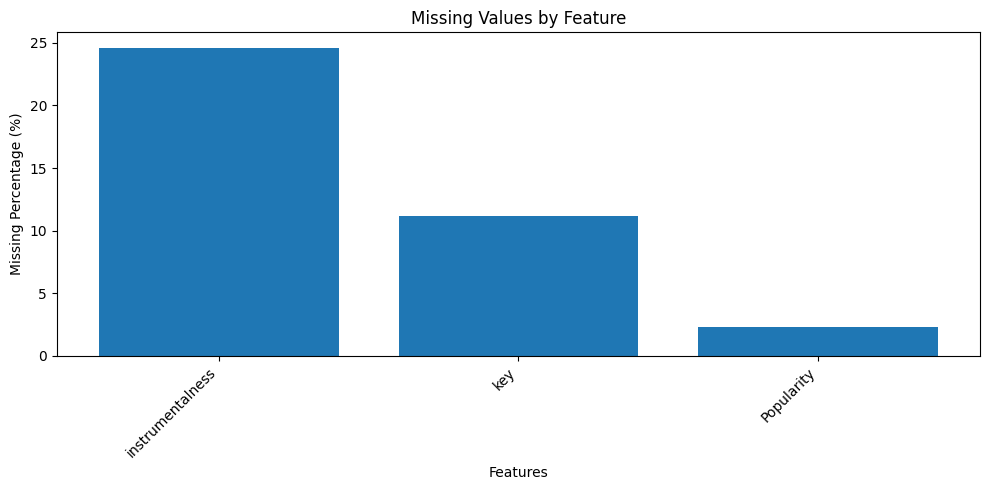

In [2]:
# CELL 3: MISSING VALUES ANALYSIS
missing_count = train.isna().sum()
missing_percent = (
    missing_count / len(train) * 100
)

missing_table = pd.DataFrame({
    "Feature": train.columns,
    "Missing Count": missing_count.values,
    "Missing Percentage": missing_percent.values
})

missing_table = missing_table.sort_values(
    "Missing Count",
    ascending=False
)

print("MISSING VALUES ANALYSIS")
display(missing_table)

# Ve bieu do
missing_plot = missing_table[
    missing_table["Missing Count"] > 0
]

plt.figure(figsize=(10, 5))

plt.bar(
    missing_plot["Feature"],
    missing_plot["Missing Percentage"]
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [3]:

# CELL 4: COMPARE FEATURE VERSIONS

feature_versions = {}

for version in ["v0", "v1", "v2"]:

    X, y, X_test, test_ids, classes = build_features(
        train,
        test,
        version=version
    )

    feature_versions[version] = {
        "X": X,
        "X_test": X_test,
        "columns": list(X.columns)
    }

    print(f"\n===== VERSION {version} =====")
    print("Train shape:", X.shape)
    print("Test shape:", X_test.shape)
    print("Missing train:", X.isna().sum().sum())
    print("Missing test:", X_test.isna().sum().sum())

summary_features = pd.DataFrame([
    {
        "Version": version,
        "Number of Features": len(data["columns"]),
        "Train Samples": len(data["X"]),
        "Test Samples": len(data["X_test"]),
        "Missing Values": int(
            data["X"].isna().sum().sum()
        )
    }
    for version, data in feature_versions.items()
])

print("\nFEATURE ENGINEERING SUMMARY")
display(summary_features)



===== VERSION v0 =====
Train shape: (14396, 14)
Test shape: (3600, 14)
Missing train: 0
Missing test: 0

===== VERSION v1 =====
Train shape: (14396, 21)
Test shape: (3600, 21)
Missing train: 0
Missing test: 0



===== VERSION v2 =====
Train shape: (14396, 32)
Test shape: (3600, 32)
Missing train: 0
Missing test: 0

FEATURE ENGINEERING SUMMARY


,Version,Number of Features,Train Samples,Test Samples,Missing Values
0,v0,14,14396,3600,0
1,v1,21,14396,3600,0
2,v2,32,14396,3600,0


In [4]:

# CELL 5: NEW FEATURES IN V2

v1_columns = set(feature_versions["v1"]["columns"])
v2_columns = set(feature_versions["v2"]["columns"])

new_features = sorted(v2_columns - v1_columns)

print("NEW FEATURES IN V2:")
for i, feature in enumerate(new_features, start=1):
    print(f"{i}. {feature}")

X_v2 = feature_versions["v2"]["X"]

print("\nV2 FEATURE SAMPLE:")
display(X_v2[new_features].head())

print("\nCHECK FEATURE QUALITY:")

assert not X_v2.isna().any().any()
assert not feature_versions["v2"]["X_test"].isna().any().any()

assert (
    list(X_v2.columns)
    == list(feature_versions["v2"]["X_test"].columns)
)

print("FEATURE ENGINEERING V2: PASSED")


NEW FEATURES IN V2:
1. acousticness_log1p
2. danceability_x_valence
3. energy_acousticness_ratio
4. instrumentalness_log1p
5. key_mode_24
6. liveness_log1p
7. loudness_clipped
8. loudness_x_energy
9. speechiness_log1p
10. tempo_group_20
11. tempo_rounded_10

V2 FEATURE SAMPLE:


,acousticness_log1p,danceability_x_valence,energy_acousticness_ratio,instrumentalness_log1p,key_mode_24,liveness_log1p,loudness_clipped,loudness_x_energy,speechiness_log1p,tempo_group_20,tempo_rounded_10
0,0.320633,0.078490,1.381443,0.003912,9,0.100750,-6.649,-3.563864,0.037392,7.0,150.0
1,0.026837,0.275500,20.080645,0.045738,23,0.098940,-5.545,-4.142115,0.083973,6.0,130.0
2,0.000968,0.370840,73.304158,0.491643,19,0.249980,-6.094,-4.899576,0.060060,7.0,160.0
3,0.645531,0.258015,0.335878,0.021076,-1,0.262364,-14.711,-4.530988,0.030723,8.0,170.0
4,0.168054,0.349735,4.025907,0.003912,6,0.191446,-5.096,-3.959592,0.222343,4.0,90.0



CHECK FEATURE QUALITY:
FEATURE ENGINEERING V2: PASSED


In [5]:

# CELL 6: FOLD-SAFE ARTIST TARGET ENCODING

import sys
import subprocess
from pathlib import Path

PROJECT_ROOT = Path(common.__file__).resolve().parent.parent
CODE_DIR = PROJECT_ROOT / "code"

print("Project:", PROJECT_ROOT)

# Verify the encoder independently on validation and test samples.
subprocess.run(
    [
        sys.executable,
        str(CODE_DIR / "02_test_target_encoding_C.py"),
    ],
    cwd=str(PROJECT_ROOT),
    check=True,
)

# Run the fold-safe ablation so feature preprocessing and nested OOF stay
# inside each outer fold. The encoder's Pipeline/CV integration is tested
# separately by 02_test_target_encoding_C.py.
print("\nRUN FOLD-SAFE ABLATION")

subprocess.run(
    [
        sys.executable,
        str(CODE_DIR / "02_ablation_foldsafe_C.py"),
    ],
    cwd=str(PROJECT_ROOT),
    check=True,
)

print("\nFOLD-SAFE ABLATION COMPLETED")


Project: C:\mayhoc\MLGroup\Music Genre Classification



RUN FOLD-SAFE ABLATION



FOLD-SAFE ABLATION COMPLETED


In [6]:

# CELL 7: ABLATION STUDY RESULTS

csv_path = PROJECT_ROOT / "evidence" / "cv_logs" / "ablation_foldsafe_C.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"Run the fold-safe ablation first: {csv_path}")

ablation_df = pd.read_csv(csv_path)
expected_versions = ["v0", "v1", "v2", "v2+TE"]
if ablation_df["Version"].tolist() != expected_versions:
    raise ValueError(
        f"Unexpected fold-safe ablation versions: {ablation_df['Version'].tolist()}"
    )

baseline_accuracy = ablation_df.loc[
    ablation_df["Version"] == "v1",
    "Accuracy"
].iloc[0]
ablation_df["Delta vs v1 (pp)"] = (
    ablation_df["Accuracy"] - baseline_accuracy
) * 100

print("FOLD-SAFE ABLATION RESULTS")
display(ablation_df.round(4))


FOLD-SAFE ABLATION RESULTS


,Version,Accuracy,Accuracy Std,Macro F1,Delta vs v1 (pp)
0,v0,0.5370,0.0058,0.5724,-2.2159
1,v1,0.5591,0.0070,0.6084,0.0000
2,v2,0.5590,0.0032,0.6088,-0.0069
3,v2+TE,0.6411,0.0053,0.6922,8.1967


FINAL ABLATION RESULTS


,Version,Accuracy,Accuracy Std,Macro F1
0,v0,0.536954,0.005811,0.572361
1,v1,0.559114,0.006972,0.608375
2,v2,0.559044,0.003184,0.608798
3,v2+TE,0.641081,0.005267,0.692182


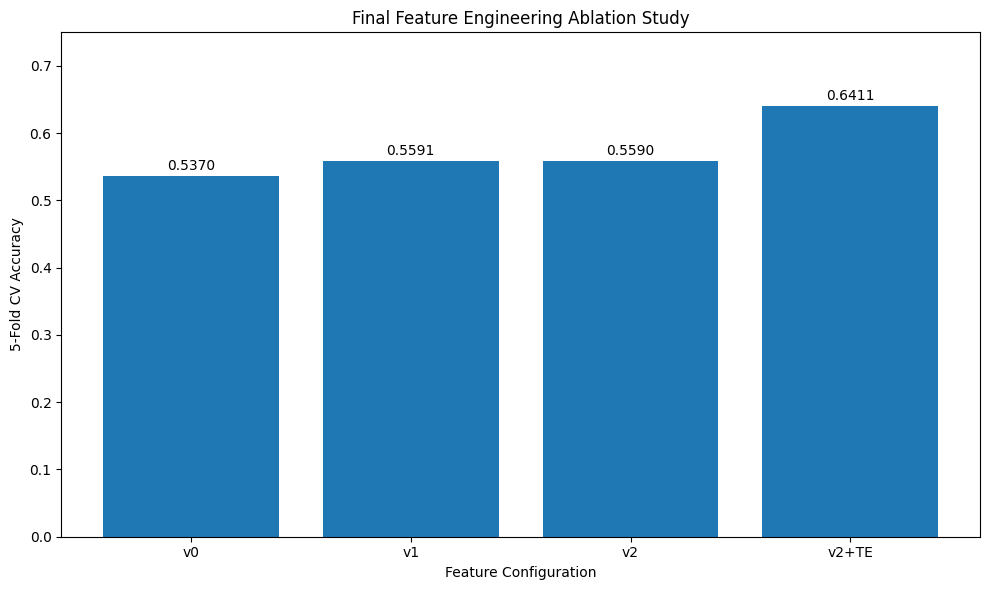

Saved: C:\mayhoc\MLGroup\Music Genre Classification\paper\figures\ablation_C.png


In [7]:

# CELL 8: FINAL FOLD-SAFE ABLATION CHART

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path(common.__file__).resolve().parent.parent

csv_path = root / "evidence" / "cv_logs" / "ablation_foldsafe_C.csv"

df = pd.read_csv(csv_path)

print("FINAL ABLATION RESULTS")
display(df)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    df["Version"],
    df["Accuracy"]
)

plt.title("Final Feature Engineering Ablation Study")
plt.xlabel("Feature Configuration")
plt.ylabel("5-Fold CV Accuracy")
plt.ylim(0, 0.75)

for bar, value in zip(bars, df["Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()

output = root / "paper" / "figures" / "ablation_C.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)



## RESULTS AND DISCUSSION

### Feature Engineering Results

Four feature configurations were evaluated using
HistGradientBoostingClassifier and Stratified 5-Fold
Cross-Validation.

The fold-safe baseline feature set v0 achieved an
accuracy of approximately 0.5370.

Version v1 improved accuracy to 0.5591 by correcting
mixed duration units, adding missing-value indicators,
and introducing artist and track frequency features.

Version v2 included log transformations, interaction
features, key-mode combinations, and tempo grouping.
Its accuracy was approximately 0.5590, nearly the same as v1.

Adding Artist Target Encoding to v2 produced an
accuracy of approximately 0.6411 and a macro F1
score of 0.6922.

This represents an improvement of approximately
8.20 percentage points over v1.

### Interpretation

Artist identity provides useful information for
music genre classification.

Target encoding creates class probability features
for each artist using smoothed class frequencies.

Nested out-of-fold encoding was used for the training
portion to reduce target leakage.

The official ablation uses the fold-safe runner:
imputation is fitted inside each outer training fold,
and target encoding uses nested out-of-fold values.
The encoder is a scikit-learn Pipeline transformer: its
fit_transform creates inner OOF values, and the shared CV
helper preserves DataFrame column names. The full ablation
runner still handles fold-local numeric preprocessing.

### Conclusion

The experiments suggest that artist-based target
encoding is a promising feature engineering technique.

Further work includes group-based validation for
unseen artists and additional model comparisons.